
# COU07506 – DIGITAL SIGNAL PROCESSING

## WEEK 3 – LAB 1B
### Convolution, Correlation and Difference Equations

**Name:** Swaum Hussen Idd

**Registration Number:** 240242406676

**Module:** Digital Signal Processing

**Department:** Computer Studies Department

**Institution:** Dar es Salaam Institute of Technology

**Academic Year:** 2026/2027


In [1]:

# WEEK 3: DSP LABORATORY SETUP

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
import time

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Week 3 DSP Laboratory environment is ready!")


Week 3 DSP Laboratory environment is ready!



## Pre-lab Preparation

### Question A

Convolve x(n) = {1, -1, 2} with
h(n) = {2, 1, 0, 1}.

Answer:

y(n) = {2, -1, 3, -1, 2, 2}

### Question B

Is y(n) = n x(n) time-invariant?

Answer:

No. The system is time-varying because shifting
the input does not produce an equivalent shift
in the output. The multiplication by n changes
the system behaviour with time.



## Task 3.1 – Convolution from the Definition

**Objective:**

To implement linear convolution using Python loops
and verify the result using NumPy's convolve function.

We will also compare the execution time of both methods.


In [2]:

# TASK 3.1: CONVOLUTION FROM THE DEFINITION

def conv(x, h):

    # Calculate output length
    N = len(x) + len(h) - 1

    # Create output array
    y = np.zeros(N)

    # Perform convolution using loops
    for n in range(N):
        for k in range(len(x)):

            if 0 <= n-k < len(h):
                y[n] += x[k] * h[n-k]

    return y


# Test convolution
x = [1, 2, 3, 1]
h = [1, 1, 1]

# Our own convolution function
result1 = conv(x, h)

# NumPy convolution
result2 = np.convolve(x, h)

print("Convolution using our function:")
print(result1)

print("\nConvolution using NumPy:")
print(result2)


Convolution using our function:
[1. 3. 6. 6. 4. 1.]

Convolution using NumPy:
[1 3 6 6 4 1]


In [3]:

# VERIFY PRE-LAB CONVOLUTION

x = [1, -1, 2]
h = [2, 1, 0, 1]

# Using our own function
answer1 = conv(x, h)

# Using NumPy
answer2 = np.convolve(x, h)

print("Our convolution function:")
print(answer1)

print("\nNumPy convolution:")
print(answer2)


Our convolution function:
[ 2. -1.  3.  3. -1.  2.]

NumPy convolution:
[ 2 -1  3  3 -1  2]


In [4]:

# COMPARE EXECUTION TIME

# Generate two random sequences
rng = np.random.default_rng(42)

x = rng.standard_normal(2000)
h = rng.standard_normal(2000)

# Time our own convolution function
start = time.perf_counter()

y1 = conv(x, h)

end = time.perf_counter()

time_manual = end - start

# Time NumPy convolution
start = time.perf_counter()

y2 = np.convolve(x, h)

end = time.perf_counter()

time_numpy = end - start

# Display results
print("EXECUTION TIME COMPARISON")
print("-------------------------")

print("Manual convolution:",
      round(time_manual, 6), "seconds")

print("NumPy convolution:",
      round(time_numpy, 6), "seconds")

print("Results are equal:",
      np.allclose(y1, y2))


EXECUTION TIME COMPARISON
-------------------------
Manual convolution: 4.21986 seconds
NumPy convolution: 0.002523 seconds
Results are equal: True



### Observation

The convolution operation was implemented using
Python loops and verified using NumPy's convolve
function.

Both methods produced the same output for the
test sequences.

The pre-lab convolution was also verified successfully.

The execution time comparison showed that NumPy's
convolution function is faster than the manually
implemented function.

This is because NumPy uses optimized numerical
operations, while the manual method performs
calculations using nested loops.

### Conclusion

Linear convolution determines the output of a
system from its input signal and impulse response.

The experiment demonstrated that manual convolution
and NumPy convolution produce equivalent results,
although their execution speeds differ.



## Task 3.2 – Smoothing a Noisy Signal by Convolution

**Objective:**

To reduce Gaussian noise from a signal using
moving-average filters of different lengths.

We will compare filters with M = 3, M = 9 and M = 25.


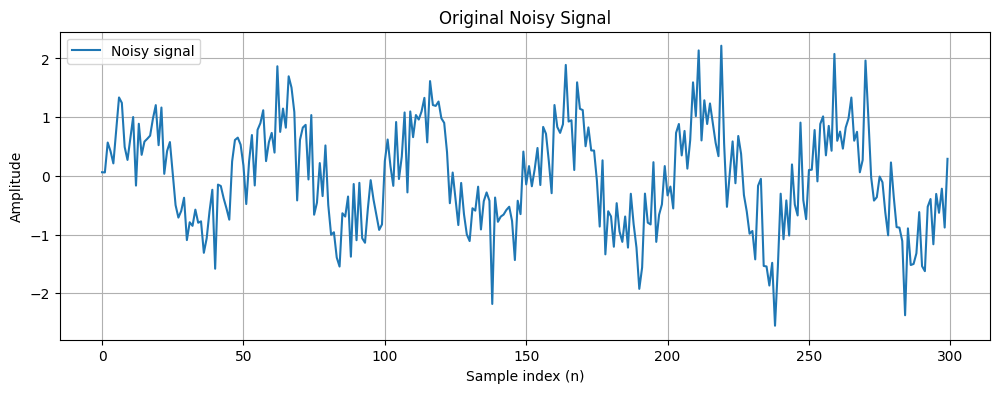

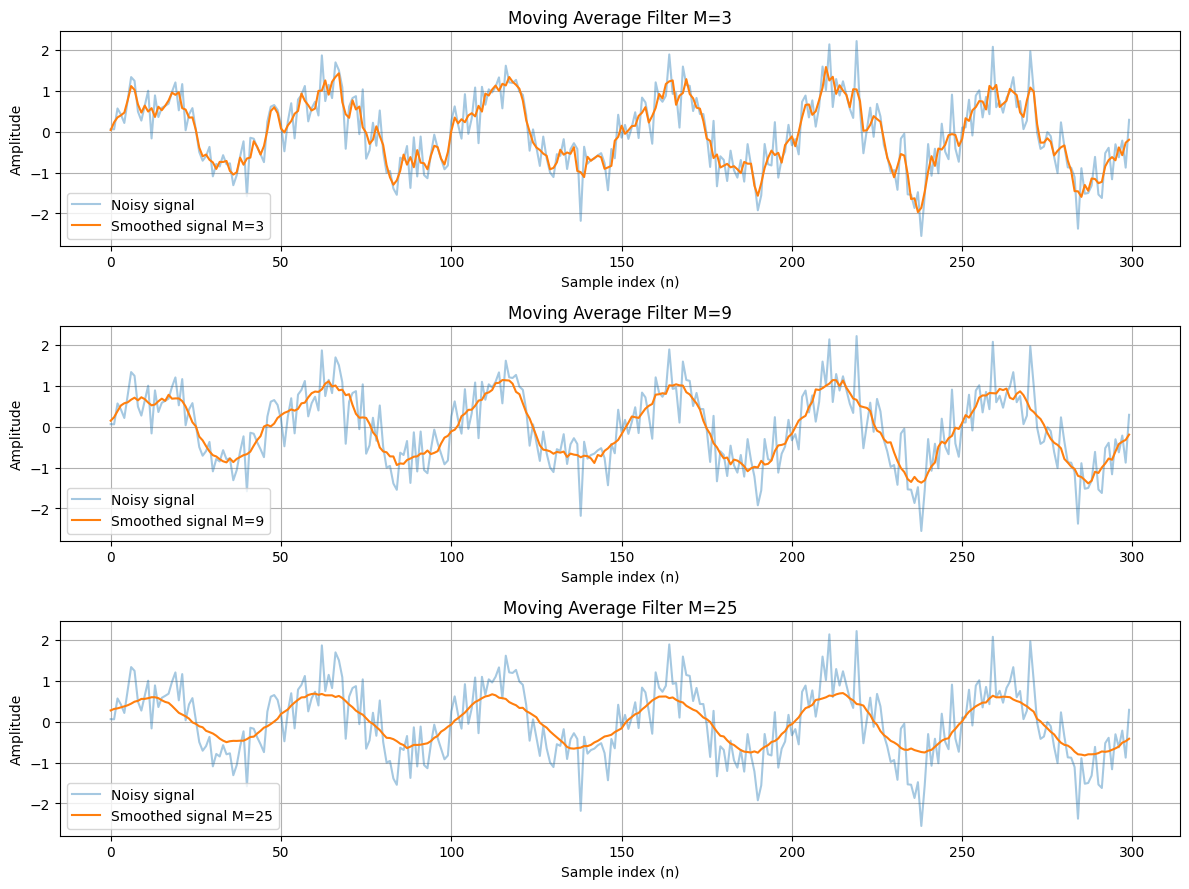

Smoothing using convolution completed!


In [5]:

# TASK 3.2: SMOOTHING A NOISY SIGNAL

# Generate sample indices
n = np.arange(300)

# Generate Gaussian noise
rng = np.random.default_rng(0)
w = rng.standard_normal(300)

# Generate original noisy signal
x = np.sin(2 * np.pi * n / 50) + 0.5 * w

# Define moving average filter sizes
M_values = [3, 9, 25]

# Plot original noisy signal
plt.figure(figsize=(12, 4))
plt.plot(n, x, label="Noisy signal")
plt.title("Original Noisy Signal")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

# Apply moving average filters
plt.figure(figsize=(12, 9))

for i, M in enumerate(M_values):

    # Create moving average filter
    h = np.ones(M) / M

    # Apply convolution
    y = np.convolve(x, h, mode="same")

    # Plot smoothed signal
    plt.subplot(3, 1, i+1)
    plt.plot(n, x, alpha=0.4, label="Noisy signal")
    plt.plot(n, y, label=f"Smoothed signal M={M}")

    plt.title(f"Moving Average Filter M={M}")
    plt.xlabel("Sample index (n)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.legend()

plt.tight_layout()
plt.show()

print("Smoothing using convolution completed!")



### Observation

The original signal contains Gaussian noise that
makes the signal appear irregular.

A moving-average filter was applied using convolution
with filter lengths M = 3, M = 9 and M = 25.

For M = 3, a small amount of noise was reduced while
most of the original signal details were preserved.

For M = 9, more noise was reduced and the signal
became smoother.

For M = 25, the signal became much smoother, but
some original signal details were distorted.

### Conclusion

Moving-average filters can reduce noise in a signal
through convolution.

Increasing the filter length improves noise reduction
but may also increase signal distortion.

Therefore, an appropriate filter length should be
selected to balance noise reduction and signal quality.



## Task 3.3 – Testing Linearity and Time-Invariance Numerically

**Objective:**

To test whether different systems satisfy
the properties of linearity and time-invariance
using Python.


In [6]:

# TASK 3.3: TESTING LINEARITY AND TIME-INVARIANCE

# Generate random input signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

# Define constants
a, b = 2.0, -3.0

# Define three systems
systems = {
    "x^2": lambda x: x**2,

    "n x(n)": lambda x: np.arange(len(x)) * x,

    "moving average": lambda x: np.convolve(
        x, np.ones(3)/3
    )[:len(x)]
}

# Test each system
for name, T in systems.items():

    # Test linearity
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Delay input by 5 samples
    xd = np.concatenate([np.zeros(5), x1])[:50]

    # Delay output by 5 samples
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    # Test time-invariance
    tinv = np.allclose(T(xd), yd)

    print(
        f"{name:15s} linear={linear} "
        f"time-invariant={tinv}"
    )


x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True



### Observation

Three systems were tested for linearity and
time-invariance using Python.

The first system, x(n)^2, was found to be nonlinear
but time-invariant because squaring does not satisfy
the linearity condition.

The second system, n*x(n), was found to be linear
but time-varying because its output depends on the
sample index n.

The third system, moving average, was found to be
both linear and time-invariant.

### Conclusion

The experiment demonstrated that digital systems
can have different properties.

A system can be linear, nonlinear, time-invariant
or time-varying depending on its mathematical
relationship between input and output.



## Task 3.4 – Finding a Hidden Delay with Cross-Correlation

**Objective:**

To estimate the time delay between a transmitted
signal and a received noisy signal using
cross-correlation.

We will also investigate how increasing noise
affects delay estimation.


CROSS-CORRELATION RESULTS
-------------------------
Actual delay: 37 samples
Estimated delay: 37 samples


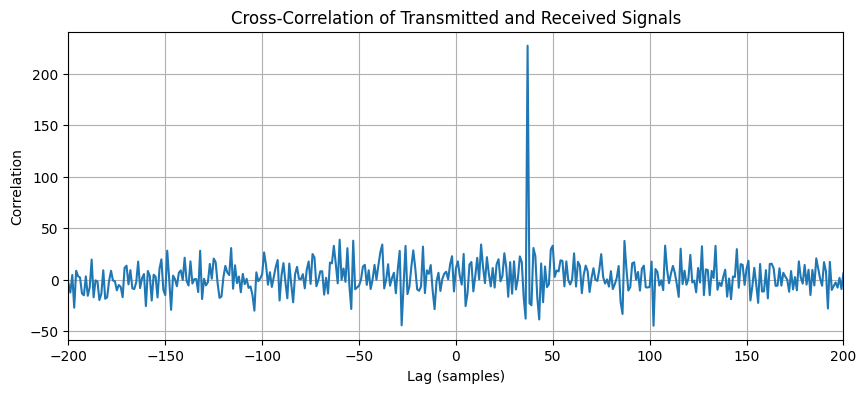

Estimated time delay: 0.037 seconds
Estimated distance: 12.691 meters


In [7]:

# TASK 3.4: FINDING A HIDDEN DELAY

# Generate transmitted signal
rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)

# Actual delay
true_delay = 37

# Generate received signal with noise
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]
y = y + 0.5*rng.standard_normal(500)

# Calculate cross-correlation
r = signal.correlate(y, x, mode="full")

# Calculate lag values
lags = signal.correlation_lags(
    len(y), len(x), mode="full"
)

# Estimate delay
estimated_delay = lags[np.argmax(r)]

print("CROSS-CORRELATION RESULTS")
print("-------------------------")
print("Actual delay:", true_delay, "samples")
print("Estimated delay:", estimated_delay, "samples")

# Plot cross-correlation
plt.figure(figsize=(10, 4))
plt.plot(lags, r)
plt.xlim(-200, 200)
plt.title("Cross-Correlation of Transmitted and Received Signals")
plt.xlabel("Lag (samples)")
plt.ylabel("Correlation")
plt.grid(True)
plt.show()

# Convert delay into distance
speed_of_sound = 343

delay_seconds = estimated_delay / fs
distance = speed_of_sound * delay_seconds

print("Estimated time delay:", delay_seconds, "seconds")
print("Estimated distance:", round(distance, 3), "meters")


In [8]:

# TEST EFFECT OF DIFFERENT NOISE LEVELS

noise_levels = [0.5, 1, 2, 4]

rng_noise = np.random.default_rng(10)

print("NOISE LEVEL TEST")
print("-------------------------")

for noise_std in noise_levels:

    # Create received signal
    noisy_y = np.concatenate(
        [np.zeros(true_delay), 0.6*x]
    )[:500]

    noisy_y += noise_std * rng_noise.standard_normal(500)

    # Calculate correlation
    corr = signal.correlate(
        noisy_y, x, mode="full"
    )

    lag = signal.correlation_lags(
        len(noisy_y), len(x), mode="full"
    )

    # Estimate delay
    delay_estimate = lag[np.argmax(corr)]

    print(
        "Noise:", noise_std,
        "| Estimated delay:", delay_estimate,
        "samples"
    )


NOISE LEVEL TEST
-------------------------
Noise: 0.5 | Estimated delay: 37 samples
Noise: 1 | Estimated delay: 37 samples
Noise: 2 | Estimated delay: 37 samples
Noise: 4 | Estimated delay: 37 samples



### Observation

Cross-correlation was used to estimate the delay
between the transmitted and received signals.

The original signal contained 500 random samples
and was transmitted with an actual delay of
37 samples.

The received signal contained additional Gaussian
noise.

The cross-correlation function helped identify
the estimated delay by locating its maximum peak.

Different noise levels were tested to investigate
their effects on delay estimation.

As noise increases, the correlation peak becomes
less clear, making accurate delay estimation
more difficult.

### Conclusion

Cross-correlation is useful for estimating the
time delay between two signals.

However, high noise levels can reduce the accuracy
of delay estimation.



## Task 3.5 – Difference Equations

**Objective:**

To calculate the impulse response of a digital
system using direct recursion and SciPy lfilter.

We will also calculate the step response and
compare its final value with the theoretical value.


In [9]:

# TASK 3.5: DIFFERENCE EQUATIONS

# Generate impulse input
N = 10
impulse = np.zeros(N)
impulse[0] = 1

# Initialize output
h_loop = np.zeros(N)

# Calculate impulse response using direct recursion
for n in range(N):

    x_current = impulse[n]

    x_previous = impulse[n-1] if n >= 1 else 0

    y_previous = h_loop[n-1] if n >= 1 else 0

    y_previous2 = h_loop[n-2] if n >= 2 else 0

    h_loop[n] = (
        x_current + x_previous
        + 0.75*y_previous
        - 0.125*y_previous2
    )

print("Impulse response using direct recursion:")
print(h_loop)


Impulse response using direct recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]


In [10]:

# Calculate impulse response using lfilter

h_filter = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    impulse
)

print("Impulse response using lfilter:")
print(h_filter)

# Compare both methods
print("\nAre both results equal?")
print(np.allclose(h_loop, h_filter))


Impulse response using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Are both results equal?
True


Closed-form impulse response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Comparison with lfilter:
True


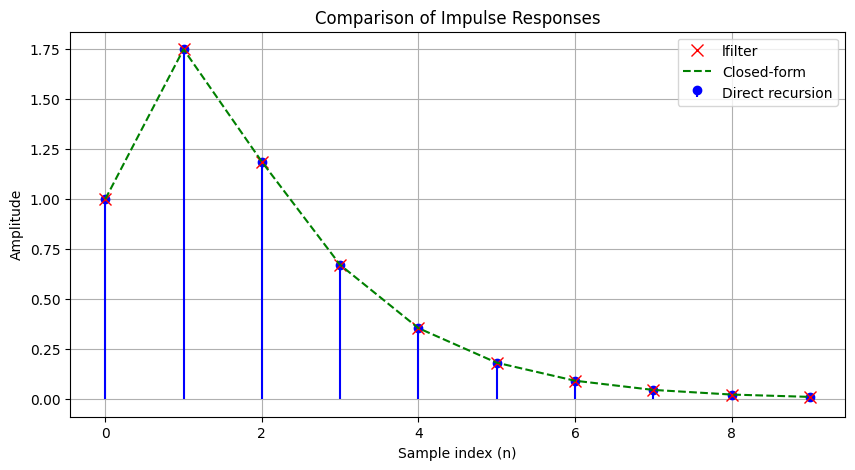

In [11]:

# Compare with the closed-form equation

n = np.arange(10)

h_closed = 6*(0.5**n) - 5*(0.25**n)

print("Closed-form impulse response:")
print(h_closed)

print("\nComparison with lfilter:")
print(np.allclose(h_filter, h_closed))

# Plot all three responses
plt.figure(figsize=(10, 5))

plt.stem(n, h_loop, linefmt="b-", markerfmt="bo",
         basefmt=" ", label="Direct recursion")

plt.plot(n, h_filter, "rx", markersize=8,
         label="lfilter")

plt.plot(n, h_closed, "g--",
         label="Closed-form")

plt.title("Comparison of Impulse Responses")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


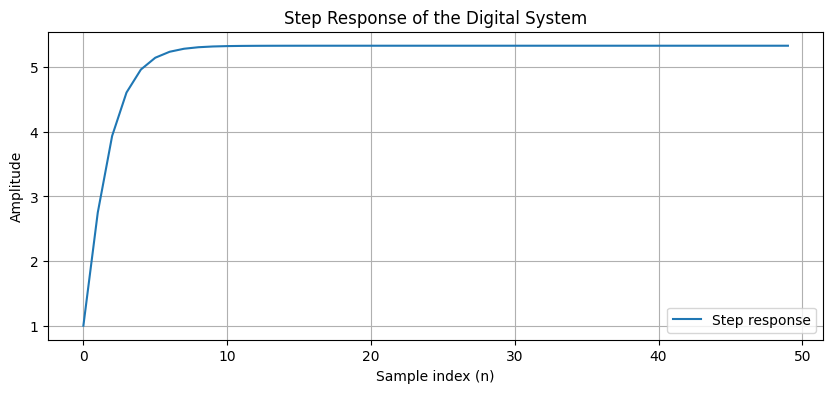

Final step response value: 5.333333333333323
Theoretical final value H(1): 5.333333333333333


In [12]:

# Calculate step response

step_input = np.ones(50)

step_response = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    step_input
)

# Plot step response
plt.figure(figsize=(10, 4))

plt.plot(step_response, label="Step response")

plt.title("Step Response of the Digital System")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

# Calculate theoretical final value
H1 = sum([1, 1]) / sum([1, -0.75, 0.125])

print("Final step response value:", step_response[-1])
print("Theoretical final value H(1):", H1)



### Observation

The impulse response was calculated using direct
recursion and the SciPy lfilter function.

Both methods produced the same results, confirming
that the difference equation was implemented correctly.

The closed-form impulse response also matched the
calculated impulse response.

The step response was calculated using a unit step
input. Its output approached the theoretical final
value of approximately 5.3333.

### Conclusion

Difference equations are used to describe digital
systems using present and previous input and
output samples.

The experiment demonstrated that direct recursion
and lfilter can produce equivalent results.

The step response also confirmed the theoretical
steady-state value of the system.



## Week 3 – Analysis Questions

### Question 1

Why is np.convolve so much faster than a double loop?

Answer:

NumPy uses optimized numerical operations implemented
in compiled code, while a manual double loop executes
each multiplication and addition through Python.
For input lengths L and M, direct convolution requires
approximately L × M multiplications.

### Question 2

Which of the three systems in Task 3.3 are LTI?

Answer:

The moving-average system is linear and
time-invariant (LTI).

The system x(n)^2 is nonlinear but time-invariant.

The system n*x(n) is linear but time-varying.

### Question 3

Give two engineering applications of cross-correlation
in Tanzania.

Answer:

1. GPS navigation: Cross-correlation can help estimate
signal arrival delays from satellites to determine
a receiver's position.

2. Water pipe leak detection: Cross-correlation of
signals from sensors at different locations can help
estimate the position of a water leakage.

### Question 4

Is the system in Task 3.5 FIR or IIR? Stable?

Answer:

The system is an Infinite Impulse Response (IIR)
system because its output depends on previous output
values.

It is stable because its impulse response decays
towards zero and its poles are inside the unit circle.
